# How to train your AI: fra statistiske modeller til nevrale nettverk

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/simeneide/how-to-train-your-ai/blob/main/workshop.ipynb)

Tech Day, Norges Bank, 6. november 2026. Simen Eide.

Vi skal prognosere **KPI-JAE neste måned**. Først bruker vi modeller som fra eller inspirert av SMART (AR, VAR, BVAR, faktormodell), men vi bygger de i Pytorch. Pytorch er et bibliotek for å modellere og tilpasse nevrale nettverk.

Poenget med denne øvelsen er å vise hvordan vi kan tolke "klassiske" statistiske modeller som nevrale nettverk. Når vi er ferdig med å implementere de klassiske modellene, skal vi se på hvordan vi kan utvide de til å faktisk bli større nettverk.

Poenget er _ikke_ å lage en modell som er bedre enn det Norges bank bruker idag, det er heller ikke å lære så mye om dataene bak øvelsen. Her er det teknisk "bygge nevrale nett" som er fokus. Bakgrunn om KPI-JAE, dataene og SMART står i README, men for workshoppen trenger vi bare å tenke at vi skal predikere KPI-JAE kolonnen basert på de andre kolonnene.

### Slik bruker du notebooken
En notebook er et dokument som blander tekst (markdown) og kode (pythong). Trykk ▶ på cellene ovenfra og ned. Ofte trenger du ikke her å skrive kode, men les igjennom og prøv gjerne å endre de for forbedringer.

Alle modeller følger de samme fire stegene som i foredraget, og koden i hver oppgave er delt opp slik:

| Steg | Spørsmål | Her |
|---|---|---|
| **1. Data** | Hva vet vi? | hvilke serier, og hvor mange måneder tilbake |
| **2. Modell** | Hvordan henger det sammen? | en funksjon med parametere: `nn.Linear`, `nn.Sequential` |
| **3. Trening** | Hvilke parametere passer best? | treningsløkka, prior (weight decay), valgt på validering |
| **4. Beslutning** | Hva gjør vi med svaret? | prognosefeil, ledertavle og prognose for oktober |

## Steg 0: Importer biblioteker vi trenger

In [11]:
# @title Oppsett: biblioteker og datafil { display-mode: "form" }
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from torch import nn

sns.set_theme()  # samme lyse stil på alle grafene
plt.rcParams["savefig.facecolor"] = "white"  # hvit bakgrunn også i mørkt tema (VS Code)
DATA = "https://raw.githubusercontent.com/simeneide/how-to-train-your-ai/main/data/forTecDay.xlsx"

## Steg 1: Data
Vi har fått et faktisk Norges-bank datasett fra Kenneth Paulsen som vi skal bruke. Det inneholder mange indikatorer og priser på månedsnivå bakover i tid.

Vi bygger hele datasettet én gang her, og alle oppgavene bruker det samme. Oppgavene velger bare hvilke kolonner modellen får se.

Først rådataene: 61 månedlige serier med indeksnivåer, kronekurs, oljepris og ledighet.

In [12]:
raw = pd.read_excel(DATA).set_index("Time")
raw.index = pd.PeriodIndex([t.replace("M", "-") for t in raw.index], freq="M")
raw = raw.loc["2001-01":]


# Vi lager noen grupper av kolonnenavn
TARGET = "MSA_PCPIJAE"
DRIVERS = {
    "kronekurs": "I44",
    "oljepris": "DS.OILBRSV",
    "importpriser": "MSA_IPK",
    "innsatsvarer": "MSA_IPI",
    "ledighet": "NAV.HL.TOT.PST.S",
}
GROUPS = [
    c for c in raw if c.startswith(("MSA_PCPIJAE_25", "KPI.KPI"))
]  # 13 hovedgrupper og 40 delindekser
print(f"{raw.shape[1]} serier, {raw.index[0]} til {raw.index[-1]}")

# Se på datasettet:
print("Siste måneder i datasettet:")
raw[[TARGET, "MSA_PCPIJAE_25_K1", "KPI.KPI.25.K041.IPR.S", *DRIVERS.values()]].tail()

61 serier, 2001-01 til 2026-09
Siste måneder i datasettet:


,MSA_PCPIJAE,MSA_PCPIJAE_25_K1,KPI.KPI.25.K041.IPR.S,I44,DS.OILBRSV,MSA_IPK,MSA_IPI,NAV.HL.TOT.PST.S
2026-05,102.8,102.670955,103.141368,110.070001,107.986667,120.912133,139.265682,2.052937
2026-06,102.7,102.193420,103.408990,112.821364,85.327727,121.244048,139.520457,2.033498
2026-07,102.9,102.088042,103.773912,113.482174,84.093913,121.751628,139.660093,2.045050
2026-08,103.3,102.457751,104.066012,111.545238,90.821905,122.080846,140.158343,2.043135
2026-09,103.5,103.550963,104.302988,110.315909,113.918182,122.535698,NaN,2.021947


### Trening, validering og test
Vi deler historien i tre: 
- **trening** (2003-2016) der modellen lærer, 
- **validering** (2017-2020) der vi kan iterere og validere forskjellige modeller, og 
- **test** (2021-) der vi ser hvor godt det gikk _helt til slutt_.

Denne tredelingen gjør vi så vi ikke overfitter modellene våre: Spesielt med nevrale nett er dette viktig: De er så parameterike at de i prinsippet kan memorere et helt datasett inn i parameterne sine uten å egentlig lære sammenhengen. Det er ikke det vi ønsker.

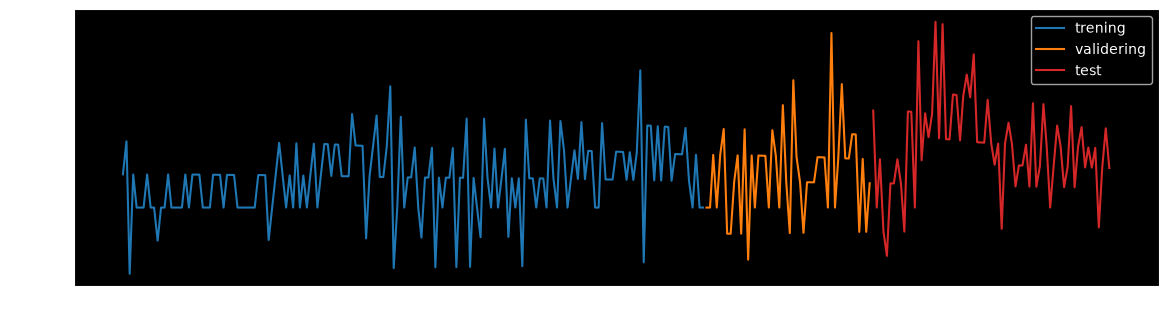

In [13]:
RATES = ["NAV.HL.TOT.PST.S"]
mm = 100 * np.log(raw.drop(columns=RATES)).diff()
mm[RATES] = raw[RATES].diff()

SPLIT = {
    "trening": ("2003-01", "2016-12"),
    "validering": ("2017-01", "2020-12"),
    "test": ("2021-01", "2100-01"),
}
_, ax = plt.subplots(figsize=(14, 3.6))
for (name, (a, b)), c in zip(SPLIT.items(), ["tab:blue", "tab:orange", "tab:red"]):
    s = mm[TARGET].loc[a:b]
    ax.plot(s.index.to_timestamp(), s, color=c, label=name)
ax.set_ylabel("Endring i KPI-JAE, %")
ax.legend()
plt.show()

### Bygge datasettet
Nå bygger vi datasettet. Én rad er én måned $t$:

- $y$ (fasiten): endringen i KPI-JAE måneden etter, $t+1$.
- $X$ (det modellen vet i måned $t$): endringen de 24 siste månedene i KPI-JAE, de 5 driverne og de 53 gruppene (59 serier, 1416 kolonner). Kolonnene heter `serie t-k`: `KPI-JAE t-0` er denne måneden, `KPI-JAE t-1` forrige måned, osv.

Alle kolonnene standardiseres med gjennomsnitt og standardavvik fra treningsperioden, så de er på samme skala. Tall vi mangler (noen serier starter sent), settes til gjennomsnittet.

In [4]:
NAMES = {TARGET: "KPI-JAE", **{v: k for k, v in DRIVERS.items()}}
NAMES |= {
    c: c.replace("MSA_PCPIJAE_25_", "gruppe ")
    .replace("KPI.KPI.25.", "delindeks ")
    .replace(".IPR.S", "")
    for c in GROUPS
}
MAX_LAG = 24  # vi lager 24 måneder tilbake for alle seriene, oppgavene velger hvor mange de bruker

X = pd.concat(
    {
        f"{NAMES[c]} t-{k}": mm[c].shift(k)
        for c in [TARGET, *DRIVERS.values(), *GROUPS]
        for k in range(MAX_LAG)
    },
    axis=1,
)
y = mm[TARGET].shift(-1).rename("KPI-JAE neste måned")

train_part = X.loc[slice(*SPLIT["trening"])]
Z = ((X - train_part.mean()) / train_part.std().replace(0, 1)).fillna(0.0)
ROWS = {name: y.loc[a:b].dropna().index for name, (a, b) in SPLIT.items()}

print(f"X: {X.shape[0]} måneder x {X.shape[1]} kolonner")
print({name: len(idx) for name, idx in ROWS.items()}, "måneder i hver del")
pd.concat([y, X[["KPI-JAE t-0", "KPI-JAE t-1", "KPI-JAE t-2", "kronekurs t-0", "oljepris t-0", "gruppe K1 t-0"]]], axis=1).loc["2026"].round(2)

X: 309 måneder x 1416 kolonner
{'trening': 168, 'validering': 48, 'test': 68} måneder i hver del


,KPI-JAE neste måned,KPI-JAE t-0,KPI-JAE t-1,KPI-JAE t-2,kronekurs t-0,oljepris t-0,gruppe K1 t-0
2026-01,0.20,0.39,0.30,0.10,-1.08,5.86,0.04
2026-02,0.29,0.20,0.39,0.30,-2.94,6.63,-0.07
2026-03,0.20,0.29,0.20,0.39,-0.95,37.47,-0.34
2026-04,0.29,0.20,0.29,0.20,-1.58,13.64,1.54
2026-05,-0.10,0.29,0.20,0.29,-1.91,-9.15,-0.44
2026-06,0.19,-0.10,0.29,0.20,2.47,-23.55,-0.47
2026-07,0.39,0.19,-0.10,0.29,0.58,-1.46,-0.10
2026-08,0.19,0.39,0.19,-0.10,-1.72,7.70,0.36
2026-09,NaN,0.19,0.39,0.19,-1.11,22.66,1.06


### Velge kolonner
Hver oppgave velger hvilke kolonner i $X$ modellen får se, med `kolonner(...)`. Du gir den navnet på hver serie og hvor mange måneder tilbake du vil ha med:

- `kolonner({"KPI-JAE": 12})` gir `KPI-JAE t-0` til `KPI-JAE t-11`: de 12 siste månedene av KPI-JAE. Det er dataene til en AR(12)-modell.
- `kolonner({"KPI-JAE": 12, "kronekurs": 3})` gir i tillegg kronekursen de 3 siste månedene.
- `grupper=2` tar med alle de 53 gruppene og delindeksene, de 2 siste månedene.

Seriene heter `KPI-JAE`, `kronekurs`, `oljepris`, `importpriser`, `innsatsvarer`, `ledighet`, og `gruppe K1` til `gruppe K13` og `delindeks K011` osv. for gruppene. Maks 24 måneder tilbake.

In [5]:
def kolonner(lags: dict[str, int], grupper: int = 0) -> list[str]:
    """Velg kolonner i X.

    lags: serienavn -> antall måneder tilbake, f.eks. {"KPI-JAE": 12, "kronekurs": 3}.
          3 betyr t-0, t-1 og t-2.
    grupper: antall måneder tilbake for alle 53 gruppene og delindeksene (0 = ingen).

    Returnerer en liste med kolonnenavn, f.eks. ["KPI-JAE t-0", "KPI-JAE t-1", ...].
    """
    lags = lags | {NAMES[g]: grupper for g in GROUPS if grupper}
    for serie, p in lags.items():
        if f"{serie} t-0" not in X:
            raise KeyError(f"Ukjent serie: {serie!r}. Velg blant {list(NAMES.values())[:6]} eller gruppene.")
        if p > MAX_LAG:
            raise ValueError(f"{serie}: maks {MAX_LAG} måneder tilbake")
    return [f"{serie} t-{k}" for serie, p in lags.items() for k in range(p)]


print("Få navnet på noen kolonner:")
print(kolonner({"KPI-JAE": 3, "kronekurs": 2}))
print("---")

print("Få X tilhørende de kolonnene:")
X[kolonner({"KPI-JAE": 3, "kronekurs": 2})]

Få navnet på noen kolonner:
['KPI-JAE t-0', 'KPI-JAE t-1', 'KPI-JAE t-2', 'kronekurs t-0', 'kronekurs t-1']
---
Få X tilhørende de kolonnene:


,KPI-JAE t-0,KPI-JAE t-1,KPI-JAE t-2,kronekurs t-0,kronekurs t-1
2001-01,NaN,NaN,NaN,NaN,NaN
2001-02,0.420127,NaN,NaN,0.035098,NaN
2001-03,-0.104124,0.420127,NaN,-0.935539,0.035098
2001-04,0.111459,-0.104124,0.420127,-0.234550,-0.935539
2001-05,0.246007,0.111459,-0.104124,-0.598583,-0.234550
...,...,...,...,...,...
2026-05,0.292255,0.195313,0.293686,-1.909610,-1.577448
2026-06,-0.097324,0.292255,0.195313,2.468919,-1.909610
2026-07,0.194553,-0.097324,0.292255,0.584005,2.468919
2026-08,0.387973,0.194553,-0.097324,-1.721554,0.584005


## Et par hjelpefunksjoner 
Før vi starter med moddellene må vi lage noen hjelpefunksjoner.

In [6]:
# @title Maskinrom: treningsløkka, evaluering og ledertavle { display-mode: "form" }
LEADERBOARD: list[dict] = []


def tensors(cols: list[str]) -> dict:
    """
    Gjør om kolonnenavn til pytorch tensorer (tenk numpy arrays) så de er klare for trening.
    """
    out = {
        name: (
            torch.tensor(Z.loc[idx, cols].values, dtype=torch.float32),
            torch.tensor(y.loc[idx].values, dtype=torch.float32),
            idx,
        )
        for name, idx in ROWS.items()
    }
    out["siste"] = torch.tensor(
        Z[cols].iloc[[-1]].values, dtype=torch.float32
    )  # siste kjente måned, for prognosen
    return out


def train(
    model: nn.Module,
    cols: list[str],
    epochs: int = 2000,
    lr: float = 0.01,
    weight_decay: float = 0.0,
    seed: int = 0,
):
    """
    Treningsløkka. Vi tar vare på vektene som traff best på valideringsperioden (early stopping).
    Trening av nevrale nett bruker gradient descent. Her har vi implementert en bare bones variant av den hvis du vil undersøke, men ideen er å regne ut førstederiverte av tapsfunksjonen med hensyn til parameterne og deretter flytte alle parametere littegrann slik at tapet blir litt mindre. Du trenger ikke forstå dette, bare tenk på `train()` som en fit() funksjon.
    """
    torch.manual_seed(seed)
    for m in model.modules():
        if hasattr(m, "reset_parameters"):
            m.reset_parameters()
    data = tensors(cols)
    (xtr, ytr, _), (xva, yva, _) = data["trening"], data["validering"]
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    hist, best, state = {"trening": [], "validering": []}, float("inf"), None
    for _ in range(epochs):
        model.train()
        opt.zero_grad()
        loss = ((model(xtr).squeeze(-1) - ytr) ** 2).mean()
        loss.backward()
        opt.step()
        model.eval()
        with torch.no_grad():
            val = ((model(xva).squeeze(-1) - yva) ** 2).mean().item()
        hist["trening"].append(loss.item() ** 0.5)
        hist["validering"].append(val**0.5)
        if val < best:
            best, state = val, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(state)
    model.eval()
    return model, data, hist


def evaluate(name: str, model: nn.Module, data: dict, hist: dict | None = None) -> None:
    """RMSE i hver periode, en graf av prognosene i testperioden, og en rad på ledertavla."""
    res = {"modell": name, "parametere": sum(p.numel() for p in model.parameters())}
    with torch.no_grad():
        for part in ["trening", "validering", "test"]:
            x, yt, idx = data[part]
            res[part] = ((model(x).squeeze(-1) - yt) ** 2).mean().item() ** 0.5
        res["prognose neste mnd"] = model(data["siste"]).item()
        x, yt, idx = data["test"]
        p = model(x).squeeze(-1).numpy()
    LEADERBOARD.append(res)
    _, axes = plt.subplots(1, 2 if hist else 1, figsize=(14 if hist else 9, 3.6))
    ax = axes[0] if hist else axes
    t = idx.to_timestamp()
    ax.plot(t, yt.numpy(), color="black", label="Faktisk")
    ax.plot(t, p, color="tab:red", label=name)
    ax.set_title(f"Testperioden: RMSE {res['test']:.3f}")
    ax.set_ylabel("Endring i KPI-JAE, %")
    ax.legend()
    if hist:
        axes[1].plot(hist["trening"], label="Trening")
        axes[1].plot(hist["validering"], label="Validering")
        axes[1].set_title("Treningsløkka: feil per runde")
        axes[1].set_xlabel("Runde")
        axes[1].set_ylabel("RMSE")
        axes[1].set_ylim(0, max(0.6, min(hist["validering"]) * 2))
        axes[1].legend()
    plt.tight_layout()
    plt.show()
    print({k: round(v, 3) if isinstance(v, float) else v for k, v in res.items()})


def leaderboard() -> pd.DataFrame:
    return (
        pd.DataFrame(LEADERBOARD)
        .drop_duplicates("modell", keep="last")
        .sort_values("validering")
        .round(3)
        .reset_index(drop=True)
    )


# Enkle referanser uten parametere
for name, p in {
    "Naiv: samme som forrige måned": mm[TARGET],
    "Snitt siste 12 mnd": mm[TARGET].rolling(12).mean(),
}.items():
    LEADERBOARD.append(
        {
            "modell": name,
            "parametere": 0,
            **{
                k: float(np.sqrt(((p.loc[idx] - y.loc[idx]) ** 2).mean()))
                for k, idx in ROWS.items()
            },
            "prognose neste mnd": float(p.iloc[-1]),
        }
    )
leaderboard()

,modell,parametere,trening,validering,test,prognose neste mnd
0,Snitt siste 12 mnd,0,0.173,0.23,0.223,0.245
1,Naiv: samme som forrige måned,0,0.258,0.35,0.292,0.193


## Oppgave 1: AR-modellen er et nevralt nett med ett lag

SMART har mange AR-modeller: neste måned er en vektet sum av de $P$ siste månedene:

$$\hat{y}_{t+1} = b + w_1 y_t + w_2 y_{t-1} + \dots + w_P y_{t-P+1}$$

I PyTorch skriver vi en modell som en klasse (`nn.Module`) med to deler:
- `__init__`: parameterne, her én vekt $w$ per måned og et konstantledd $b$. `nn.Parameter` betyr «et tall treningen skal justere».
- `forward`: selve likningen, hvordan prognosen regnes ut fra $X$.

Tegnet som et nettverk er det $P$ noder inn og én ut, og vektene er strekene mellom dem. Et nevralt nett med ett lag.

**Prøv:** endre `P` (antall måneder modellen ser tilbake). Hva skjer med testfeilen? Hvilke måneder får mest vekt?

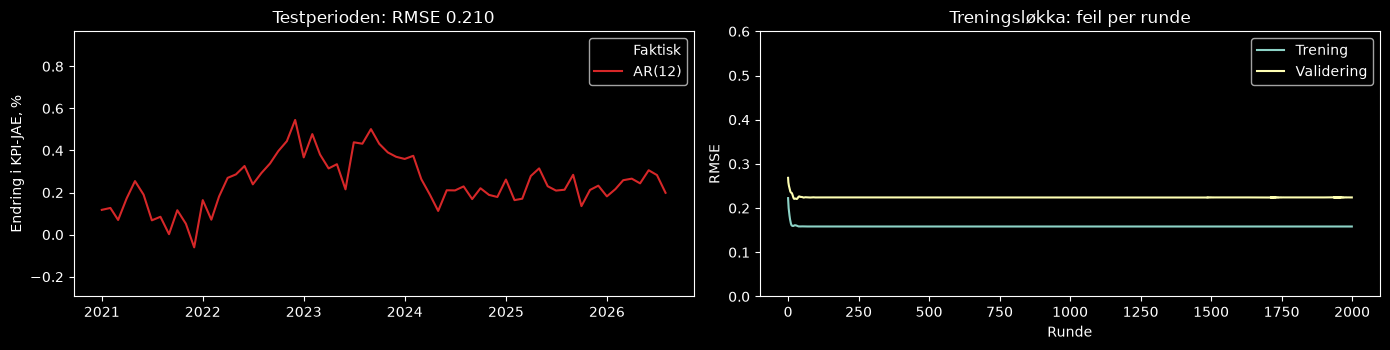

{'modell': 'AR(12)', 'parametere': 13, 'trening': 0.16, 'validering': 0.221, 'test': 0.21, 'prognose neste mnd': 0.113}


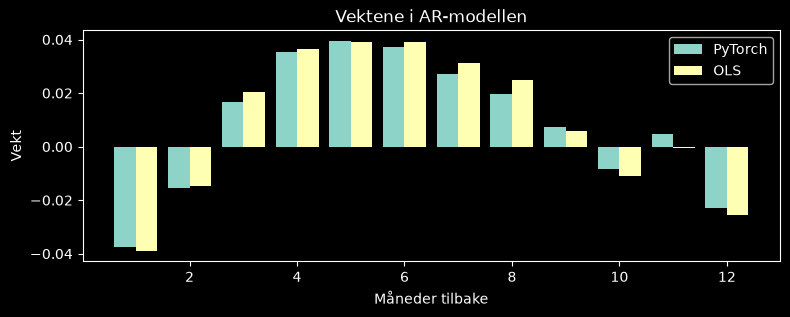

In [7]:
# 1. Data: de P siste månedene av KPI-JAE
P = 12  # @param {type:"slider", min:1, max:24, step:1}
cols_ar = kolonner({"KPI-JAE": P})

# 2. Modell: én vekt per måned, pluss et konstantledd
class AR(nn.Module):
    def __init__(self, P: int):
        super().__init__()
        self.w = nn.Parameter(torch.zeros(P))  # w_1 ... w_P
        self.b = nn.Parameter(torch.zeros(1))  # konstantledd

    def forward(self, x):
        return x @ self.w + self.b  # b + w_1 y_t + w_2 y_t-1 + ...


ar = AR(P)

# 3. Trening
EPOCHS = 2000  # @param {type:"integer"}
LR = 0.01  # @param {type:"number"}
ar, data, hist = train(ar, cols_ar, epochs=EPOCHS, lr=LR)

# 4. Beslutning: hvor godt traff den, og hva sier den om neste måned?
evaluate(f"AR({P})", ar, data, hist)

# Samme svar som minste kvadraters metode (OLS)?
xtr, ytr, _ = data["trening"]
ols = torch.linalg.lstsq(
    torch.cat([xtr, torch.ones(len(xtr), 1)], 1), ytr.unsqueeze(1)
).solution.squeeze()
plt.figure(figsize=(9, 3))
plt.bar(
    np.arange(1, P + 1) - 0.2,
    ar.w.detach().numpy(),
    width=0.4,
    label="PyTorch",
)
plt.bar(np.arange(1, P + 1) + 0.2, ols[:-1].numpy(), width=0.4, label="OLS")
plt.xlabel("Måneder tilbake")
plt.ylabel("Vekt")
plt.title("Vektene i AR-modellen")
plt.legend()
plt.show()

## Oppgave 2: VAR og en prior

En VAR-likning tar med andre serier: kronekurs, olje, importpriser, ledighet. Med `MED_GRUPPER` tar vi også med 53 delindekser av KPI. Da får modellen flere parametere enn vi har måneder å trene på.

**Prøv:**
1. Skru på `MED_GRUPPER` med `WEIGHT_DECAY = 0`. Se på grafen til høyre: treningsfeilen går ned, valideringsfeilen går opp. Det er **overtilpasning**.
2. Øk `WEIGHT_DECAY`. Det er det samme som en Bayesiansk prior (som i BVAR): vektene trekkes mot null. Når blir testfeilen best?

21 kolonner, 168 måneder å trene på


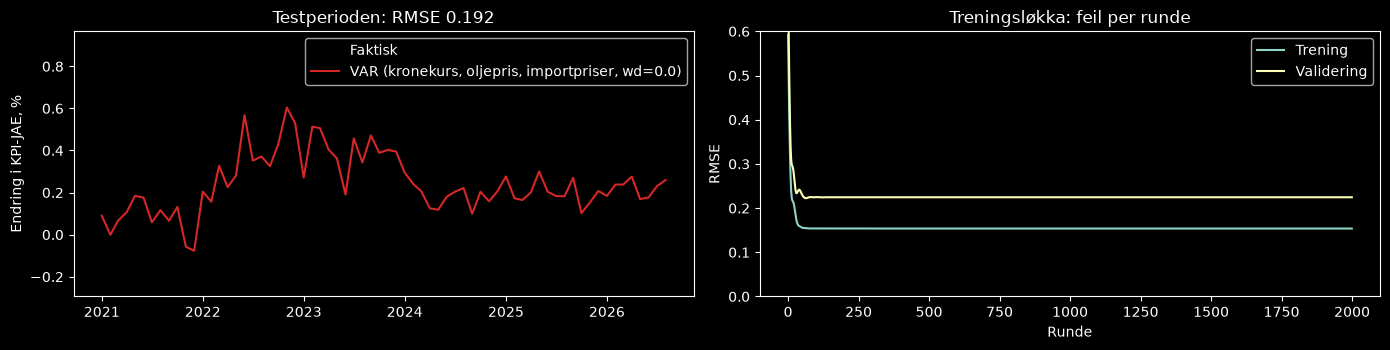

{'modell': 'VAR (kronekurs, oljepris, importpriser, wd=0.0)', 'parametere': 22, 'trening': 0.155, 'validering': 0.222, 'test': 0.192, 'prognose neste mnd': 0.156}


In [8]:
# 1. Data: KPI-JAE pluss drivere, og eventuelt alle delindeksene
kronekurs = True  # @param {type:"boolean"}
oljepris = True  # @param {type:"boolean"}
importpriser = True  # @param {type:"boolean"}
innsatsvarer = False  # @param {type:"boolean"}
ledighet = False  # @param {type:"boolean"}
MED_GRUPPER = False  # @param {type:"boolean"}

chosen = [
    k
    for k, v in {
        "kronekurs": kronekurs,
        "oljepris": oljepris,
        "importpriser": importpriser,
        "innsatsvarer": innsatsvarer,
        "ledighet": ledighet,
    }.items()
    if v
]
cols_var = kolonner({"KPI-JAE": 12, **dict.fromkeys(chosen, 3)}, grupper=2 if MED_GRUPPER else 0)
print(f"{len(cols_var)} kolonner, {len(ROWS['trening'])} måneder å trene på")
# 2. Modell: fortsatt én vekt per kolonne. Det er samme klasse som AR, og PyTorch har den ferdig: nn.Linear
var = nn.Linear(len(cols_var), 1)

# 3. Trening: weight decay er prioren som trekker vektene mot null
WEIGHT_DECAY = 0.0  # @param [0.0, 0.01, 0.1, 0.3, 1.0, 3.0] {type:"raw"}
var, data, hist = train(var, cols_var, weight_decay=WEIGHT_DECAY)

# 4. Beslutning
evaluate(
    f"VAR ({', '.join(chosen) or 'ingen drivere'}{', grupper' if MED_GRUPPER else ''}, wd={WEIGHT_DECAY})",
    var,
    data,
    hist,
)

## Oppgave 3: fra faktormodell til nevralt nett

En faktormodell komprimerer mange serier til noen få **faktorer**, og prognoserer fra dem. Som klasse har den to lag: `faktorer` gjør $n$ kolonner om til $R$ faktorer, og `prognose` gjør faktorene om til én prognose. Det midterste laget er et **skjult lag**, en flaskehals. Etter treningen kan vi se på faktorene over tid.

Legg til en ikke-lineær funksjon (ReLU) i det skjulte laget, og vi har et ekte nevralt nettverk.

**Prøv:** endre antall faktorer `R`, bytt `AKTIVERING` til ReLU, og legg til `DROPOUT` (skru av tilfeldige noder under trening, en annen type regularisering).

Faktormodell(
  (faktorer): Linear(in_features=133, out_features=3, bias=True)
  (aktivering): ReLU()
  (dropout): Dropout(p=0.0, inplace=False)
  (prognose): Linear(in_features=3, out_features=1, bias=True)
)


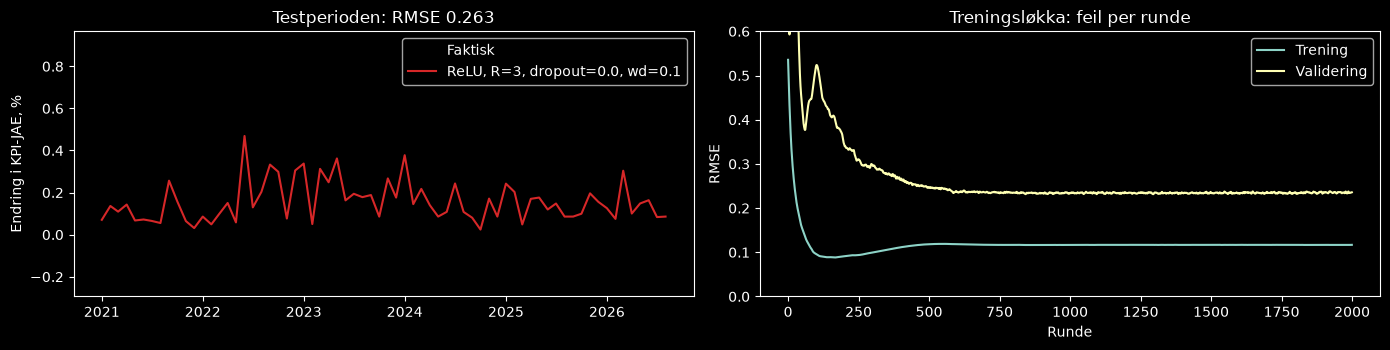

{'modell': 'ReLU, R=3, dropout=0.0, wd=0.1', 'parametere': 406, 'trening': 0.117, 'validering': 0.231, 'test': 0.263, 'prognose neste mnd': 0.069}


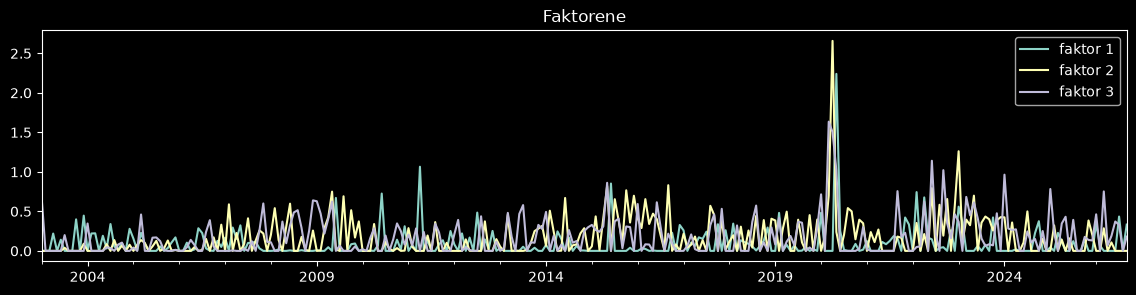

In [9]:
# 1. Data: alt vi har
cols_big = kolonner({"KPI-JAE": 12, **dict.fromkeys(DRIVERS, 3)}, grupper=2)

# 2. Modell: input -> R faktorer (skjult lag) -> prognose
R = 3  # @param {type:"slider", min:1, max:64, step:1}
AKTIVERING = "ReLU" #"ingen (faktormodell)"  # @param ["ingen (faktormodell)", "ReLU", "Tanh"]
DROPOUT = 0.0  # @param {type:"slider", min:0, max:0.8, step:0.1}
class Faktormodell(nn.Module):
    def __init__(self, n_inn: int, R: int, aktivering: nn.Module, dropout: float = 0.0):
        super().__init__()
        self.faktorer = nn.Linear(n_inn, R)  # n kolonner -> R faktorer
        self.aktivering = aktivering  # Identity = faktormodell, ReLU/Tanh = nevralt nett
        self.dropout = nn.Dropout(dropout)
        self.prognose = nn.Linear(R, 1)  # R faktorer -> prognose

    def forward(self, x):
        f = self.aktivering(self.faktorer(x))
        return self.prognose(self.dropout(f))


act = {"ingen (faktormodell)": nn.Identity(), "ReLU": nn.ReLU(), "Tanh": nn.Tanh()}[AKTIVERING]
net = Faktormodell(len(cols_big), R, act, DROPOUT)
print(net)

# 3. Trening
WEIGHT_DECAY_3 = 0.1  # @param [0.0, 0.01, 0.1, 0.3, 1.0, 3.0] {type:"raw"}
net, data, hist = train(net, cols_big, lr=0.003, weight_decay=WEIGHT_DECAY_3)

# 4. Beslutning
evaluate(
    f"{AKTIVERING}, R={R}, dropout={DROPOUT}, wd={WEIGHT_DECAY_3}", net, data, hist
)

# Faktorene over tid: hva har modellen lært å se etter?
with torch.no_grad():
    faktorer = net.aktivering(net.faktorer(torch.tensor(Z.loc["2003":, cols_big].values, dtype=torch.float32)))
pd.DataFrame(faktorer.numpy(), index=Z.loc["2003":].index.to_timestamp(), columns=[f"faktor {i + 1}" for i in range(R)]).plot(figsize=(14, 3), title="Faktorene")
plt.show()

## Oppgave 4: slå AR

Ingen av modellene over slår AR-modellen lett. Kan du? Bygg din egen modell under. Alt er lov, men velg modell på **valideringsfeilen**, ikke testfeilen. Ellers jukser du med framtiden.

Snarvei: når lagene bare kommer etter hverandre, kan du bruke `nn.Sequential` i stedet for å skrive en klasse. Det er det samme som en klasse der `forward` sender $X$ gjennom lagene i rekkefølge.

Idéer: færre eller flere lag, bare noen av gruppene, kortere historikk (`p_target`), flere skjulte lag, kombiner prognosene fra flere modeller (som SMART gjør).

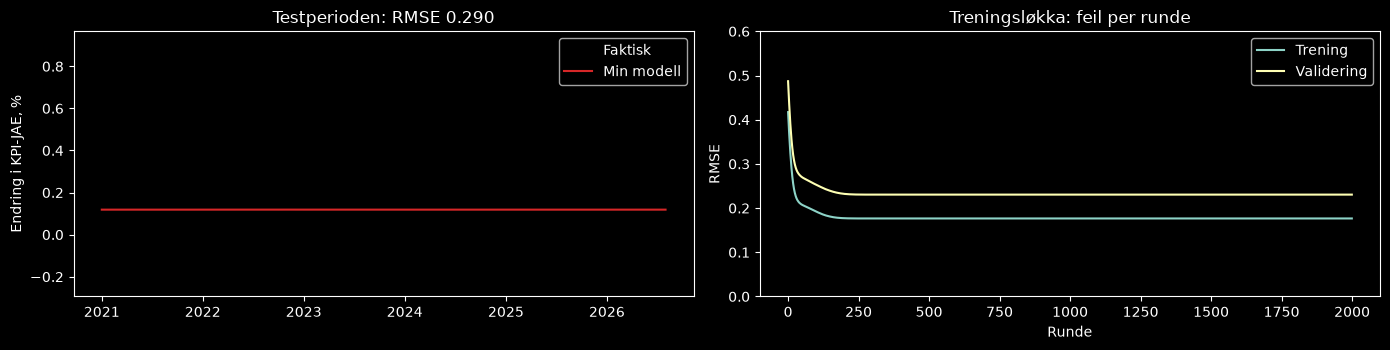

{'modell': 'Min modell', 'parametere': 225, 'trening': 0.177, 'validering': 0.231, 'test': 0.29, 'prognose neste mnd': 0.119}


In [10]:
NAVN = "Min modell"  # @param {type:"string"}

# 1. Data
cols_mine = kolonner({"KPI-JAE": 6, "kronekurs": 3, "importpriser": 3})

# 2. Modell: nn.Sequential er en klasse der forward sender x gjennom lagene i rekkefølge
mine = nn.Sequential(
    nn.Linear(len(cols_mine), 16),
    nn.ReLU(),
    nn.Linear(16, 1),
)
# 3. Trening
mine, data, hist = train(mine, cols_mine, lr=0.003, weight_decay=0.3)

# 4. Beslutning
evaluate(NAVN, mine, data, hist)

## Ledertavla

Sortert etter valideringsfeil. Den som er best på validering, er den vi ville valgt. Stemmer det med test?

In [ ]:
leaderboard()

## Steg 4: Beslutning. Hva blir KPI-JAE i oktober?

Modellen som var best på validering, gir en prognose for oktober. SSB publiserer tallet 10. november.

In [ ]:
lb = leaderboard()
best = lb.iloc[0]
level = raw[TARGET]
oct_level = level.iloc[-1] * np.exp(best["prognose neste mnd"] / 100)
yoy = 100 * (oct_level / level.loc[str(level.index[-1] - 11)] - 1)
print(f"Beste modell på validering: {best['modell']}")
print(
    f"Prognose for {level.index[-1] + 1}: {best['prognose neste mnd']:+.2f} % fra måneden før, {yoy:.1f} % fra samme måned i fjor (sesongjustert)"
)